In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface
import nilearn.plotting

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [ ]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
results_dir = os.path.join(project_dir, '...', '...')

In [ ]:
## demographics
demo = pd.read_csv(os.path.join(results_dir, '...', '...', 'demo.csv'), index_col=0)
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## ctx
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', '...', 'ctx_tle_durill.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', '...', 'ctx_ige_durill.csv'), index_col=0)

## sv
sv_tle = pd.read_csv(os.path.join(results_dir, '...', '...', 'sv_tle_durill.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', '...', 'sv_ige_durill.csv'), index_col=0)

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    'my_rdbu',
    [
        '#174fa0',  
        '#2f89c2',  
        '#f7f7f7',  
        '#df5948',  
        '#ad0c28'   
    ],
    N=256
)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## Effects of disease duration in males

In [180]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige},
}

male_diagnosis = {}

for epi in ['tle', 'ige']:
    male_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        male_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        male_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col='durill', ao_col='ao', sex_col='Sex',
            age_col='Age', icv_col='ICV', gender='male', correlate_variable='durill'
        )

In [181]:
## reorganize the results

epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

metric_map = {
    't': 't_values', 'p': 'p_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

male_metrics = {}

for biomarker in biomarkers:
    for metric_name, result_key in metric_map.items():

        stacked_values = []

        for epi in epi_types:
            values = male_diagnosis[epi][biomarker][result_key]
            values = np.asarray(values).flatten()

            stacked_values.append(values)

        male_metrics[f'{metric_name}_{biomarker}'] = np.vstack(stacked_values)

In [ ]:
## Save

metrics_to_save = ['t', 'p', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
epi_types = ['tle', 'ige']

epi_index = {epi: i for i, epi in enumerate(epi_types)}

biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'males')
os.makedirs(output_base, exist_ok=True)

for epi in epi_types:

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    epi_idx = epi_index[epi]

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]
        for metric in metrics_to_save:

            key = f'{metric}_{biomarker}'
            values = male_metrics[key][epi_idx, :]

            df = pd.DataFrame({f'{metric}_value': values}, index=index_cols            )
            df.index.name = 'region'
            df['analysis'] = 'disease duration effect'
            df['predictor'] = 'disease duration'
            df['sex'] = 'male'
            df['diagnosis'] = epi.upper()
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True            )

Cortical thickness in TLE

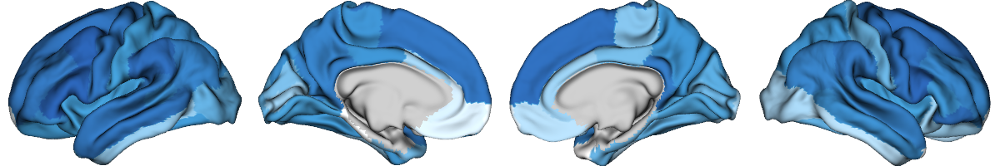

In [183]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(male_metrics['t_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-6,6))

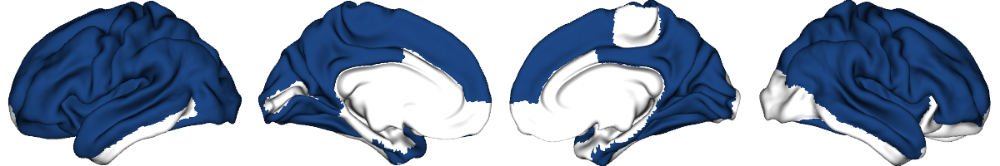

In [20]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [21]:
## Check which areas are significant
q_ctx_tle = pd.Series(male_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_entorhinal',
       'L_fusiform', 'L_inferiorparietal', 'L_isthmuscingulate',
       'L_lateraloccipital', 'L_lateralorbitofrontal', 'L_lingual',
       'L_middletemporal', 'L_paracentral', 'L_parsopercularis',
       'L_parsorbitalis', 'L_parstriangularis', 'L_postcentral',
       'L_posteriorcingulate', 'L_precentral', 'L_precuneus',
       'L_rostralmiddlefrontal', 'L_superiorfrontal', 'L_superiorparietal',
       'L_superiortemporal', 'L_supramarginal', 'L_temporalpole',
       'L_transversetemporal', 'L_insula', 'R_bankssts',
       'R_caudalmiddlefrontal', 'R_cuneus', 'R_entorhinal', 'R_fusiform',
       'R_inferiorparietal', 'R_isthmuscingulate', 'R_lingual',
       'R_middletemporal', 'R_parahippocampal', 'R_parsopercularis',
       'R_parsorbitalis', 'R_parstriangularis', 'R_pericalcarine',
       'R_postcentral', 'R_posteriorcingulate', 'R_precentral', 'R_precuneus',
       'R_rostralmiddlefrontal', 'R_superiorfront

In [22]:
len(q_ctx_tle[q_ctx_tle < 0.05])

52

In [24]:
# get the t values range for TLE in males
male_metrics['t_ctx'][0].min(), male_metrics['t_ctx'][0].max()

(-6.6231460361847425, 0.08820103811581456)

In [25]:
# get the strongest effects (t values) for p significant regions
t_ctx_tle = pd.Series(male_metrics['t_ctx'][0], index=ctx_tle.columns, name="t")

tle_ctx = pd.DataFrame({
    "t": t_ctx_tle,
    "q-value": q_ctx_tle
})

tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_ctx.head()

,t,q-value
region,,
L_parsopercularis,-6.623146,6.775718e-09
L_parstriangularis,-6.414765,1.206383e-08
L_caudalmiddlefrontal,-6.323447,1.389026e-08
R_parsopercularis,-5.836251,1.728758e-07
L_supramarginal,-5.430005,1.122880e-06


IGE

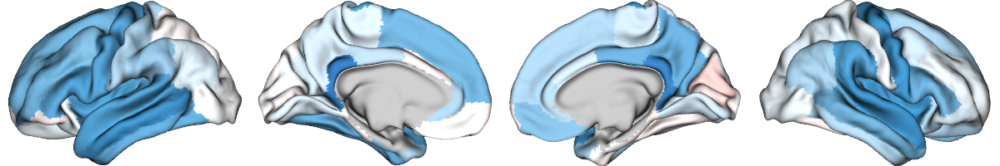

In [28]:
# plot t values in IGE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(male_metrics['t_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

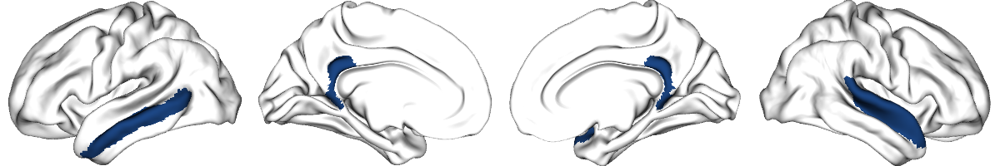

In [32]:
# plot p-sig areas in IGE
p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [33]:
## Check which areas are significant
q_ctx_ige = pd.Series(male_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_isthmuscingulate', 'L_middletemporal', 'R_isthmuscingulate',
       'R_superiortemporal'],
      dtype='object')

In [34]:
# get the t values range for IGE in males
male_metrics['t_ctx'][1].min(), male_metrics['t_ctx'][1].max()

(-4.359862368698263, 0.9050294231520267)

In [41]:
# get the t values for p significant regions for IGE in males
t_ctx_ige = pd.Series(male_metrics['t_ctx'][1], index=ctx_ige.columns, name='pFDR')

ige_ctx = pd.DataFrame({
    "t": t_ctx_ige,
    "q-value": q_ctx_ige
})

ige_sig_ctx = ige_ctx[ige_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
ige_sig_ctx

,t,q-value
L_isthmuscingulate,-4.359862,0.003912
R_isthmuscingulate,-4.085188,0.004904
L_middletemporal,-3.163246,0.043645
R_superiortemporal,-3.159630,0.043645


Subcortical volumes in TLE

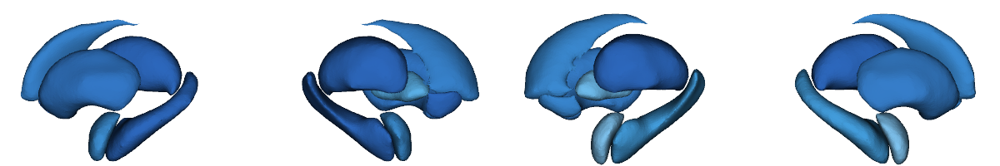

In [35]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['t_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

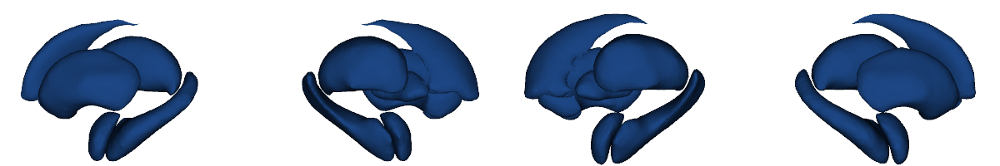

In [36]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [37]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(male_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object', name='region')

In [38]:
# get the t values range for TLE in males
male_metrics['t_sv'][0].min(), male_metrics['t_sv'][0].max()

(-7.458292624910082, -2.157283389271541)

In [42]:
# get the strongest effects (t values) for p significant subcortical regions for TLE in males
t_sv_tle = pd.Series(male_metrics['t_sv'][0], index=sv_tle.columns, name="t")

tle_sv = pd.DataFrame({
    "t": t_sv_tle,
    "q-value": q_sv_tle
})

tle_sig_sv = tle_sv[tle_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_sv.head()

,t,q-value
region,,
Lthal,-7.458293,6.307103e-12
Rthal,-6.684660,4.775905e-10
Laccumb,-6.153969,7.767810e-09
Lhippo,-5.920765,2.218132e-08
Lput,-5.199101,8.503445e-07


IGE

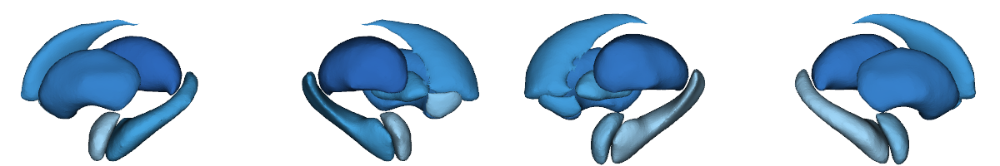

In [43]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['t_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

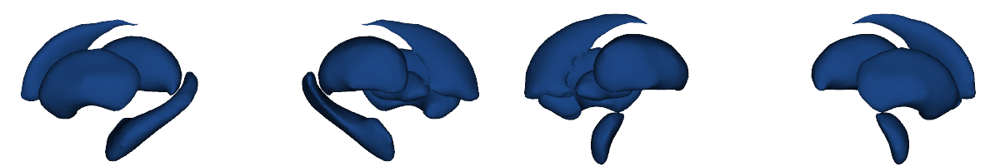

In [44]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), ventricles=False, zoom=1.8,  interactive=False, embed_nb=True, 
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [45]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(male_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05]

Lcaud      0.002050
Lhippo     0.005621
Lpal       0.004426
Lput       0.000091
Lthal      0.000005
Raccumb    0.003531
Ramyg      0.040292
Rcaud      0.003363
Rpal       0.008760
Rput       0.000089
Rthal      0.000020
Name: pFDR, dtype: float64

In [47]:
male_metrics['t_sv'][1].min(), male_metrics['t_sv'][1].max()

(-5.817170668106327, -1.7009970415883986)

In [49]:
t_sv_ige = pd.Series(male_metrics['t_sv'][1], index=sv_ige.columns, name="t")

ige_sv = pd.DataFrame({
    "t": t_sv_ige,
    "q-value": q_sv_ige
})

ige_sig_sv = ige_sv[ige_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
ige_sig_sv.head()

,t,q-value
Lthal,-5.817171,0.000005
Rthal,-5.226435,0.000020
Rput,-4.688455,0.000089
Lput,-4.598358,0.000091
Lcaud,-3.581730,0.002050


## Effects of disease duration in females

In [50]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

female_diagnosis = {}

for epi in ['tle', 'ige']:
    female_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        female_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        female_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col='durill', ao_col='ao', sex_col='Sex',
            age_col='Age', icv_col='ICV', gender='female', correlate_variable='durill'
        )

In [51]:
## reorganize the results

epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

metric_map = {
    't': 't_values', 'p': 'p_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

female_metrics = {}

for biomarker in biomarkers:
    for metric_name, result_key in metric_map.items():
        stacked_values = []

        for epi in epi_types:
            values = female_diagnosis[epi][biomarker][result_key]
            values = np.asarray(values).flatten()

            stacked_values.append(values)

        female_metrics[f'{metric_name}_{biomarker}'] = np.vstack(stacked_values)

In [ ]:
## Save 

metrics_to_save = ['t', 'p', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
epi_types = ['tle', 'ige']

epi_index = {epi: i for i, epi in enumerate(epi_types)}

biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'females')
os.makedirs(output_base, exist_ok=True)

for epi in epi_types:

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    epi_idx = epi_index[epi]

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]
        for metric in metrics_to_save:
            key = f'{metric}_{biomarker}'
            values = female_metrics[key][epi_idx, :]

            df = pd.DataFrame({f'{metric}_value': values}, index=index_cols)
            df.index.name = 'region'

            # annotation
            df['analysis'] = 'disease duration effect'
            df['predictor'] = 'disease duration'
            df['sex'] = 'female'
            df['diagnosis'] = epi.upper()
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

Cortical thickness in TLE

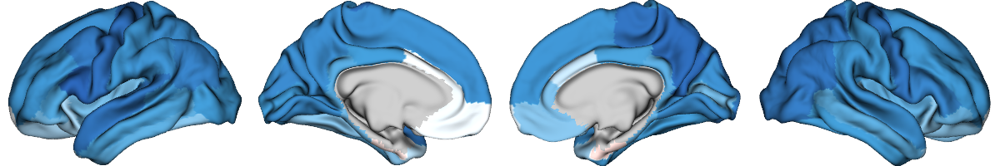

In [54]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(female_metrics['t_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

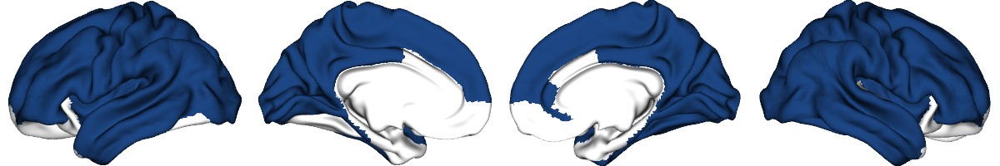

In [57]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [58]:
q_ctx_tle = pd.Series(female_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_inferiorparietal',
       'L_inferiortemporal', 'L_isthmuscingulate', 'L_lateraloccipital',
       'L_lingual', 'L_middletemporal', 'L_parahippocampal', 'L_paracentral',
       'L_parsopercularis', 'L_parsorbitalis', 'L_parstriangularis',
       'L_pericalcarine', 'L_postcentral', 'L_posteriorcingulate',
       'L_precentral', 'L_precuneus', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_superiorparietal', 'L_superiortemporal',
       'L_supramarginal', 'L_transversetemporal', 'L_insula', 'R_bankssts',
       'R_caudalmiddlefrontal', 'R_cuneus', 'R_fusiform', 'R_inferiorparietal',
       'R_inferiortemporal', 'R_isthmuscingulate', 'R_lateraloccipital',
       'R_lingual', 'R_middletemporal', 'R_parahippocampal', 'R_paracentral',
       'R_parsopercularis', 'R_parsorbitalis', 'R_parstriangularis',
       'R_pericalcarine', 'R_postcentral', 'R_posteriorcingulate',
       'R_precentral', 'R_precuneus', 'R_rostralanteri

In [60]:
len(q_ctx_tle[q_ctx_tle < 0.05])

53

In [61]:
# get the t values range for TLE in females
female_metrics['t_ctx'][0].min(), female_metrics['t_ctx'][0].max()

(-5.870531530779132, 0.7938211974848797)

In [ ]:
t_ctx_tle = pd.Series(female_metrics['t_ctx'][0], index=ctx_tle.columns, name="t")

tle_ctx = pd.DataFrame({
    "t": t_ctx_tle,
    "q-value": q_ctx_tle
})

tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_ctx.head()

,t,q-value
region,,
L_parsopercularis,-5.870532,5.077671e-07
R_precuneus,-5.564731,1.388551e-06
L_precentral,-5.309853,3.598602e-06
R_paracentral,-5.217898,4.347188e-06
R_inferiorparietal,-5.038515,6.864438e-06


IGE

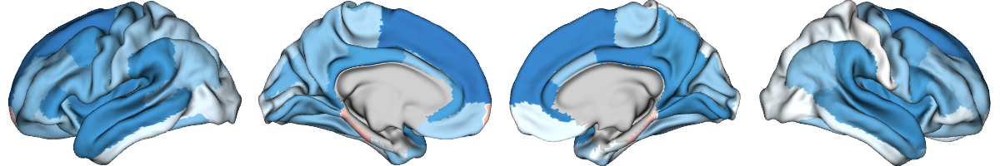

In [63]:
# plot t values in IGE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(female_metrics['t_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

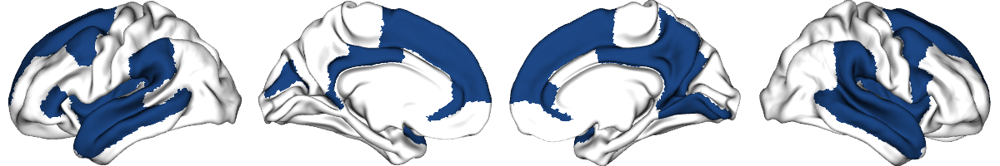

In [68]:
# plot p-sig areas in IGE

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [69]:
q_ctx_ige = pd.Series(female_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_caudalmiddlefrontal', 'L_cuneus', 'L_isthmuscingulate',
       'L_middletemporal', 'L_parstriangularis', 'L_posteriorcingulate',
       'L_rostralanteriorcingulate', 'L_superiorfrontal', 'L_superiortemporal',
       'L_supramarginal', 'L_insula', 'R_bankssts', 'R_caudalmiddlefrontal',
       'R_isthmuscingulate', 'R_lingual', 'R_middletemporal',
       'R_parsopercularis', 'R_posteriorcingulate', 'R_precuneus',
       'R_rostralanteriorcingulate', 'R_superiorfrontal', 'R_superiortemporal',
       'R_supramarginal', 'R_insula'],
      dtype='object')

In [70]:
len(q_ctx_ige[q_ctx_ige < 0.05])

24

In [71]:
female_metrics['t_ctx'][1].min(), female_metrics['t_ctx'][1].max()

(-4.720992624118562, 1.5625161295521137)

In [76]:
t_ctx_ige = pd.Series(female_metrics['t_ctx'][1], index=ctx_ige.columns, name='pFDR')

ige_ctx = pd.DataFrame({
    "t": t_ctx_ige,
    "q-value": q_ctx_ige
})

ige_sig_ctx = ige_ctx[ige_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
ige_sig_ctx

,t,q-value
L_superiorfrontal,-4.720993,0.000465
R_superiorfrontal,-4.276826,0.001362
R_posteriorcingulate,-4.005799,0.002182
R_rostralanteriorcingulate,-3.967850,0.002182
L_insula,-3.601460,0.006435
R_superiortemporal,-3.424001,0.006988
L_middletemporal,-3.414708,0.006988
R_isthmuscingulate,-3.410395,0.006988
L_superiortemporal,-3.403158,0.006988
R_insula,-3.210753,0.010582


subcortical volumes

TLE

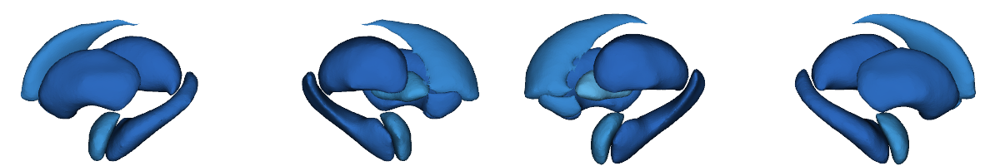

In [72]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['t_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

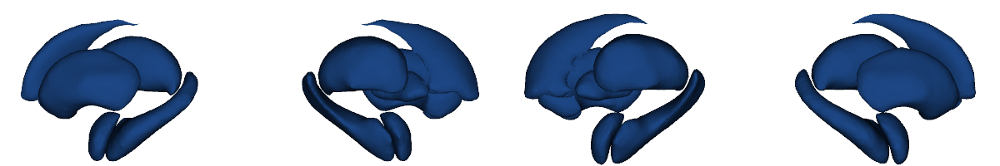

In [73]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [74]:
q_sv_tle = pd.Series(female_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object', name='region')

In [75]:
female_metrics['t_sv'][0].min(), female_metrics['t_sv'][0].max()

(-8.128092976288915, -2.578961841094431)

In [77]:
# get the strongest effects (t values) 
t_sv_tle = pd.Series(female_metrics['t_sv'][0], index=sv_tle.columns, name="t")

tle_sv = pd.DataFrame({
    "t": t_sv_tle,
    "q-value": q_sv_tle
})

tle_sig_sv = tle_sv[tle_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_sv.head()

,t,q-value
region,,
Lthal,-8.128093,3.983084e-14
Rthal,-7.348573,5.033704e-12
Rhippo,-6.012729,1.542749e-08
Lput,-5.833515,3.226242e-08
Rput,-5.733718,4.219604e-08


IGE

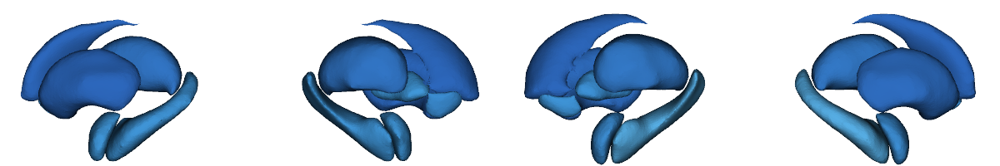

In [78]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['t_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-6, 6))


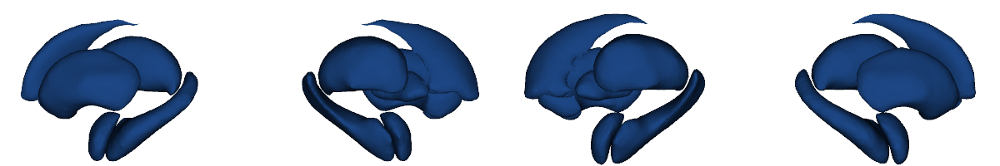

In [79]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [80]:
q_sv_ige = pd.Series(female_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [81]:
female_metrics['t_sv'][1].min(), female_metrics['t_sv'][1].max()

(-6.700660477105224, -2.7192583123839054)

In [82]:
t_sv_ige = pd.Series(female_metrics['t_sv'][1], index=sv_ige.columns, name="t")

ige_sv = pd.DataFrame({
    "t": t_sv_ige,
    "q-value": q_sv_ige
})

ige_sig_sv = ige_sv[ige_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
ige_sig_sv.head()

,t,q-value
Lcaud,-6.700660,7.274028e-09
Rcaud,-6.670160,7.274028e-09
Lput,-6.162584,5.504844e-08
Rput,-5.677456,3.879877e-07
Lthal,-5.296264,1.691829e-06


## Effects of age of onset in males

In [83]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

male_diagnosis = {}

for epi in ['tle', 'ige']:
    male_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        male_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        male_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col='durill', ao_col='ao', age_col='Age',
            sex_col='Sex', icv_col='ICV', gender='male', correlate_variable='ao'
        )

In [84]:
## reorganize the results
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

metric_map = {
    't': 't_values', 'p': 'p_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

male_metrics = {}

for biomarker in biomarkers:
    for metric_name, result_key in metric_map.items():

        stacked_values = []

        for epi in epi_types:
            values = male_diagnosis[epi][biomarker][result_key]
            values = np.asarray(values).flatten()
            
            stacked_values.append(values)

        male_metrics[f'{metric_name}_{biomarker}'] = np.vstack(stacked_values)

In [ ]:
## Save 

metrics_to_save = ['t', 'p', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
epi_types = ['tle', 'ige']

epi_index = {epi: i for i, epi in enumerate(epi_types)}

biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'males')

os.makedirs(output_base, exist_ok=True)

for epi in epi_types:

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    epi_idx = epi_index[epi]

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f'{metric}_{biomarker}'
            values = male_metrics[key][epi_idx, :]

            df = pd.DataFrame({f'{metric}_value': values}, index=index_cols            )
            df.index.name = 'region'

            df['analysis'] = 'age of onset effect'
            df['predictor'] = 'age of onset'
            df['sex'] = 'male'
            df['diagnosis'] = epi.upper()
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

Cortical thickness in TLE

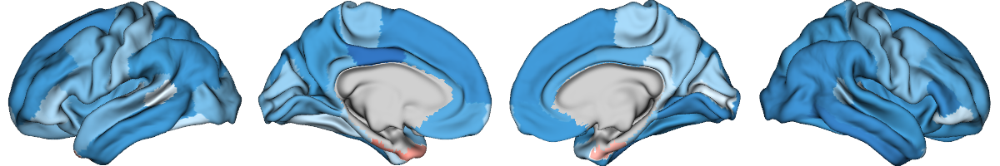

In [90]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(male_metrics['t_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

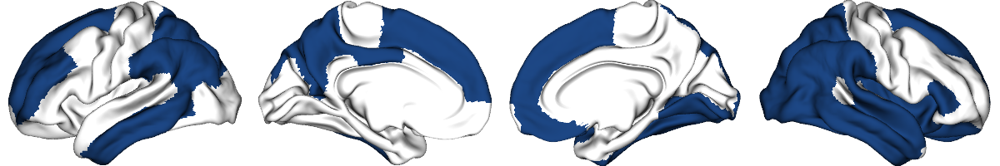

In [94]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [95]:
q_ctx_tle = pd.Series(male_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_inferiorparietal', 'L_inferiortemporal', 'L_middletemporal',
       'L_posteriorcingulate', 'L_precuneus', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_superiorparietal', 'L_supramarginal',
       'R_fusiform', 'R_inferiorparietal', 'R_inferiortemporal',
       'R_lateraloccipital', 'R_lateralorbitofrontal', 'R_lingual',
       'R_medialorbitofrontal', 'R_middletemporal', 'R_parstriangularis',
       'R_superiorfrontal', 'R_superiorparietal', 'R_superiortemporal',
       'R_supramarginal', 'R_insula'],
      dtype='object', name='region')

In [96]:
len(q_ctx_tle[q_ctx_tle < 0.05])

23

In [97]:
male_metrics['t_ctx'][0].min(), male_metrics['t_ctx'][0].max()

(-4.298479786134913, 1.907217250808567)

In [98]:
t_ctx_tle = pd.Series(male_metrics['t_ctx'][0], index=ctx_tle.columns, name="t")

tle_ctx = pd.DataFrame({
    "t": t_ctx_tle,
    "q-value": q_ctx_tle
})

tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_ctx.head(15)

,t,q-value
region,,
L_posteriorcingulate,-4.298480,0.001432
R_inferiortemporal,-3.705361,0.008062
R_parstriangularis,-3.256238,0.024124
R_middletemporal,-3.127469,0.024124
R_lingual,-3.071634,0.024124
R_lateraloccipital,-3.059387,0.024124
L_superiorfrontal,-3.007582,0.024124
R_inferiorparietal,-3.001121,0.024124
R_superiorfrontal,-2.882544,0.028183


IGE

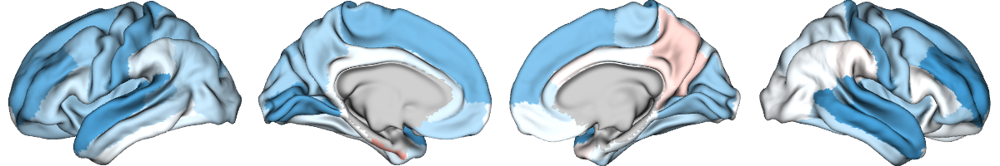

In [100]:
# plot t values in IGE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(male_metrics['t_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

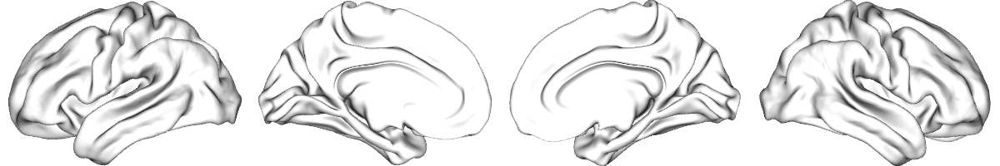

In [101]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [102]:
q_ctx_ige = pd.Series(male_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05]

Series([], Name: pFDR, dtype: float64)

In [103]:
male_metrics['t_ctx'][1].min(), male_metrics['t_ctx'][1].max()

(-2.4617152066917196, 1.5044963828427997)

Subcortical volumes in TLE

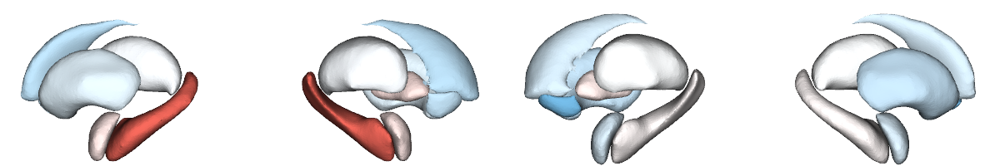

In [105]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['t_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

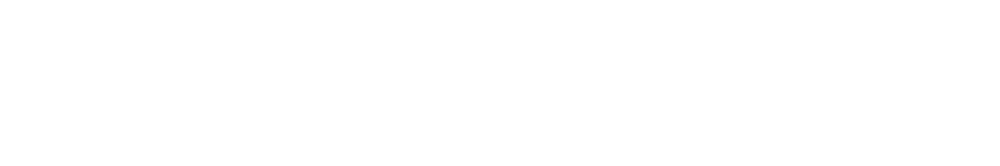

In [106]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [107]:
q_sv_tle = pd.Series(male_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object', name='region')

In [108]:
male_metrics['t_sv'][0].min(), male_metrics['t_sv'][0].max()

(-1.883988788823296, 2.724771471143123)

IGE

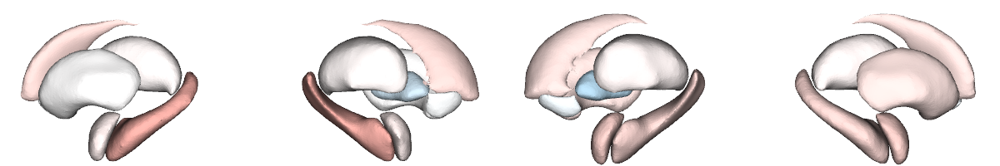

In [109]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['t_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

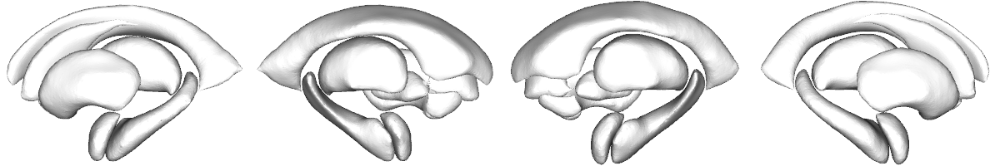

In [110]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), ventricles=False, zoom=1.8, nan_color=(1, 1, 1, 1), interactive=False, embed_nb=True, 
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [111]:
q_sv_ige = pd.Series(male_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05]

Series([], Name: pFDR, dtype: float64)

In [112]:
# get the cohen's d values range for IGE in males
male_metrics['t_sv'][1].min(), male_metrics['t_sv'][1].max()

(-0.9911105878629083, 1.3282833387547037)

## Effects of age of onset in females

In [188]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

female_diagnosis = {}

for epi in ['tle', 'ige']:
    female_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        female_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        female_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col='durill', ao_col='ao', age_col='Age',
            sex_col='Sex', icv_col='ICV', gender='female', correlate_variable='ao'
        )

In [189]:
## reorganize the results

epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

metric_map = {
    't': 't_values', 'p': 'p_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

female_metrics = {}

for biomarker in biomarkers:
    for metric_name, result_key in metric_map.items():
        stacked_values = []

        for epi in epi_types:
            values = female_diagnosis[epi][biomarker][result_key]
            values = np.asarray(values).flatten()

            stacked_values.append(values)

        female_metrics[f'{metric_name}_{biomarker}'] = np.vstack(stacked_values)

In [ ]:
## Save 

metrics_to_save = ['t', 'p', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
epi_types = ['tle', 'ige']

epi_index = {epi: i for i, epi in enumerate(epi_types)}

biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'females')
os.makedirs(output_base, exist_ok=True)

for epi in epi_types:

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    epi_idx = epi_index[epi]

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f'{metric}_{biomarker}'
            values = female_metrics[key][epi_idx, :]

            df = pd.DataFrame({f'{metric}_value': values}, index=index_cols)
            df.index.name = 'region'

            df['analysis'] = 'age of onset effect'
            df['predictor'] = 'age of onset'
            df['sex'] = 'female'
            df['diagnosis'] = epi.upper()
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

Cortical thickness in TLE

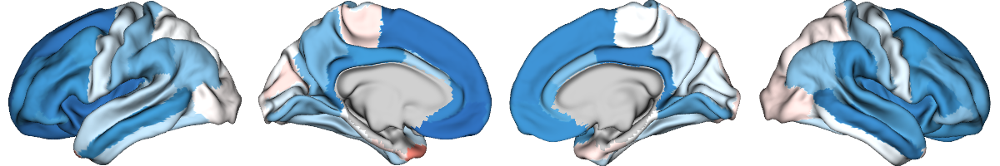

In [191]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(female_metrics['t_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

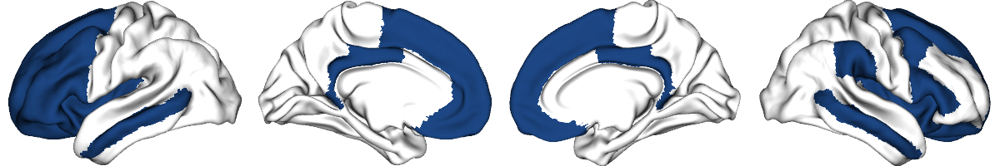

In [194]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [195]:
## Check which areas are significant
q_ctx_tle = pd.Series(female_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_caudalmiddlefrontal', 'L_isthmuscingulate', 'L_lateralorbitofrontal',
       'L_medialorbitofrontal', 'L_middletemporal', 'L_parsopercularis',
       'L_parsorbitalis', 'L_parstriangularis', 'L_posteriorcingulate',
       'L_rostralanteriorcingulate', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_frontalpole', 'L_insula',
       'R_caudalmiddlefrontal', 'R_isthmuscingulate', 'R_lateralorbitofrontal',
       'R_medialorbitofrontal', 'R_middletemporal', 'R_parsopercularis',
       'R_parstriangularis', 'R_posteriorcingulate', 'R_superiorfrontal',
       'R_supramarginal', 'R_frontalpole', 'R_insula'],
      dtype='object', name='region')

In [196]:
len(q_ctx_tle[q_ctx_tle < 0.05])

26

In [197]:
female_metrics['t_ctx'][0].min(), female_metrics['t_ctx'][0].max()

(-4.453143720819216, 2.03443418663751)

In [198]:
t_ctx_tle = pd.Series(female_metrics['t_ctx'][0], index=ctx_tle.columns, name="t")

tle_ctx = pd.DataFrame({
    "t": t_ctx_tle,
    "q-value": q_ctx_tle
})

tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_ctx.head(20)

,t,q-value
region,,
L_medialorbitofrontal,-4.453144,0.000696
L_insula,-4.277779,0.000742
L_superiorfrontal,-4.136195,0.000742
L_lateralorbitofrontal,-4.120089,0.000742
L_frontalpole,-3.534579,0.006016
R_insula,-3.465315,0.006056
L_rostralanteriorcingulate,-3.426245,0.006056
R_posteriorcingulate,-3.403751,0.006056
L_isthmuscingulate,-3.258290,0.008558


IGE

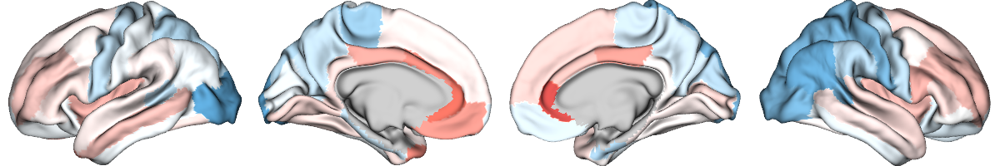

In [123]:
# plot t values in IGE
# label_text = ['TLE', 'IGE']

t_ctx_surf = parcel_to_surface(female_metrics['t_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

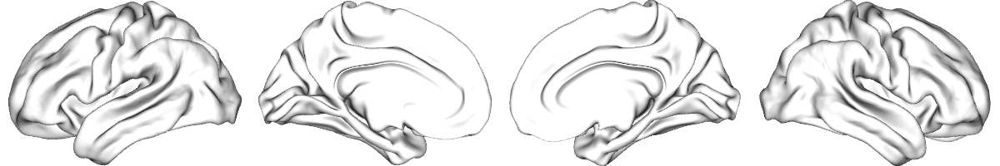

In [124]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [125]:
q_ctx_ige = pd.Series(female_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index([], dtype='object')

In [126]:
len(q_ctx_ige[q_ctx_ige < 0.05])

0

In [127]:
female_metrics['t_ctx'][1].min(), female_metrics['t_ctx'][1].max()

(-2.118166939942975, 3.259912142910777)

Subcortical volumes in TLE

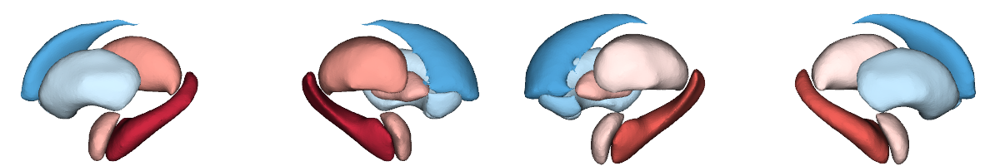

In [199]:
# plot t values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['t_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

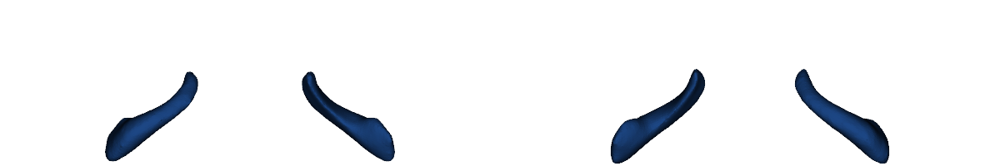

In [200]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [201]:
q_sv_tle = pd.Series(female_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Lhippo', 'Rhippo'], dtype='object', name='region')

In [202]:
female_metrics['t_sv'][0].min(), female_metrics['t_sv'][0].max()

(-2.374310933316446, 4.756777446986093)

In [204]:
t_sv_tle = pd.Series(female_metrics['t_sv'][0], index=sv_tle.columns, name="t")

tle_sv = pd.DataFrame({
    "t": t_sv_tle,
    "q-value": q_sv_tle
})

tle_sig_sv = tle_sv[tle_sv["q-value"] < 0.05].sort_values(by="t", ascending=True)
tle_sig_sv.head()

,t,q-value
region,,
Rhippo,3.046178,0.016993
Lhippo,4.756777,0.000035


IGE

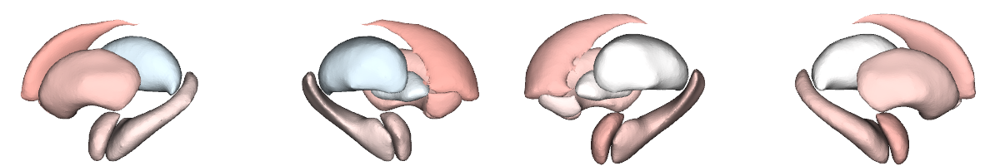

In [132]:
# plot t values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['t_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

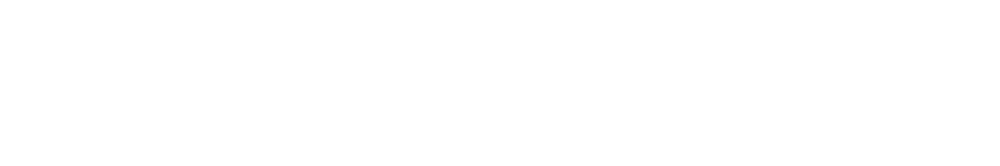

In [133]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [134]:
q_sv_ige = pd.Series(female_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index([], dtype='object')

In [135]:
female_metrics['t_sv'][1].min(), female_metrics['t_sv'][1].max()

(-0.4690141052134734, 1.3681856459229866)

## Clinical variables-by sex interaction effects

In [205]:
# glm comparison
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['duration', 'duration_sex_interaction', 'ao', 'ao_sex_interaction']

results = {}
for epi in ['tle', 'ige']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill='durill',
                ao='ao', age='Age', sex='Sex', icv='ICV'
            )

2026-09-01 16:12:52,913 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


2026-09-01 16:12:52,933 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-01 16:12:52,956 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-01 16:12:52,974 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-01 16:12:52,997 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [206]:
## reorganize the results

comparison_types = ['duration', 'duration_sex_interaction', 'ao', 'ao_sex_interaction']

epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

metric_map = {
    't': 't_values', 'p': 'p_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            stacked_values = []

            for comparison_type in comparison_types:
                values = results[epi][biomarker][comparison_type][result_key]
                values = np.asarray(values).flatten()

                stacked_values.append(values)

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = np.vstack(stacked_values)

In [ ]:
## Save 

metrics_to_save = ['t', 'p', 'q', 'beta', 'ci_lower', 'ci_upper']
epi_to_save = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

interaction_map = {'sex_x_duration': 1, 'sex_x_age_of_onset': 3}

output_base = os.path.join(results_dir, '...', 'sex_clinical_interaction_effect')
os.makedirs(output_base, exist_ok=True)

for interaction_name, row_idx in interaction_map.items():

    interaction_dir = os.path.join(output_base, interaction_name    )
    os.makedirs(interaction_dir, exist_ok=True)

    for epi in epi_to_save:

        epi_dir = os.path.join(interaction_dir, epi.upper())
        os.makedirs(epi_dir, exist_ok=True)

        for biomarker in biomarkers:
            index_cols = biomarker_index_map[biomarker]

            for metric in metrics_to_save:

                key = f"{metric}_{epi}_{biomarker}"

                if key not in result_dicts:
                    continue

                values_all = result_dicts[key]
                values = values_all[row_idx, :]

                df = pd.DataFrame({f'{metric}_value': values}, index=index_cols                )
                df.index.name = 'region'

                df['analysis'] = 'sex interaction with continuous predictor'
                df['interaction'] = interaction_name
                df['predictor'] = ('disease duration' if interaction_name == 'sex_x_duration' else 'age of onset')
                df['diagnosis'] = epi.upper()
                df['metric'] = metric
                df['biomarker'] = biomarker

                out_name = f'{metric}_{biomarker}.csv'
                df.to_csv(os.path.join(epi_dir, out_name), index=True)

### TLE results visualization

#### cortical thickness

##### Sex duration interaction effects

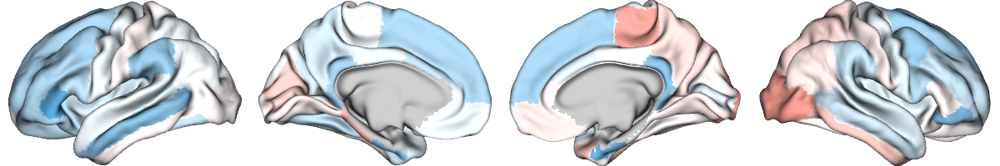

In [208]:
# plot t values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

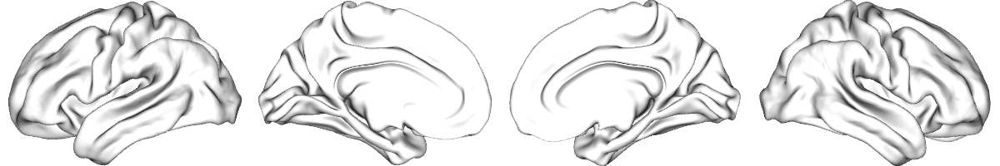

In [209]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [210]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object', name='region')

In [211]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [212]:
result_dicts['t_tle_ctx'][1].min(), result_dicts['t_tle_ctx'][1].max()

(-2.642714692216105, 2.047940240354115)

Sex * age of onset interaction effects 

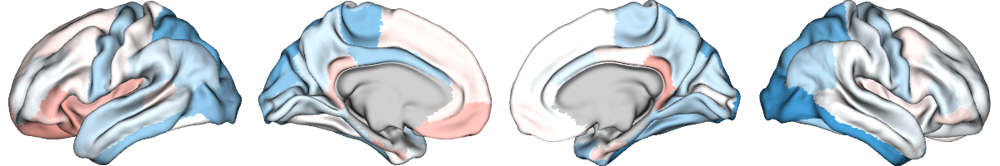

In [213]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][3], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

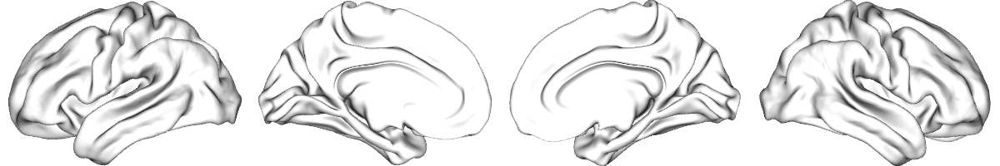

In [214]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [215]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object', name='region')

In [216]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [217]:
result_dicts['t_tle_ctx'][3].min(), result_dicts['t_tle_ctx'][3].max()

(-2.609743148064903, 1.5465450221741224)

subcortical volume

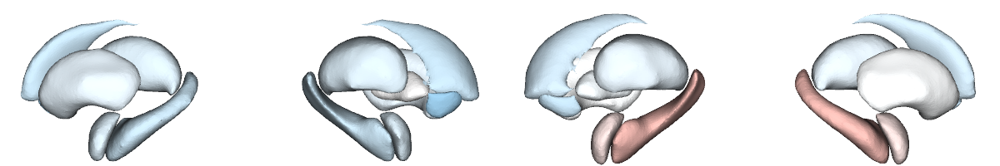

In [218]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['t_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

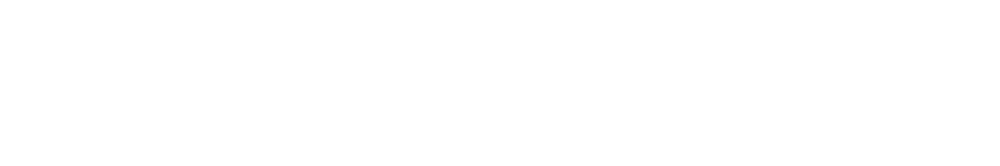

In [220]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

Sex* age of onset interaction effects in TLE

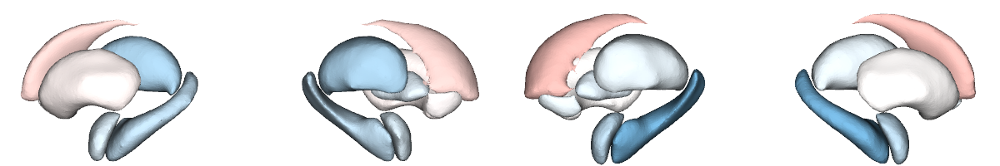

In [219]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['t_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

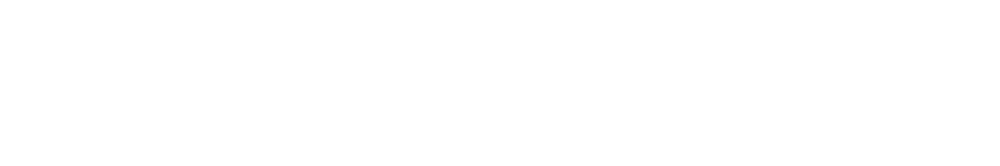

In [221]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [222]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object', name='region')

In [223]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [224]:
result_dicts['t_tle_sv'][3].min(), result_dicts['t_tle_sv'][3].max()

(-1.8352839993881582, 1.0916605716625805)

### IGE results visualization

#### Cortical thickness

##### Sex duration interaction effects

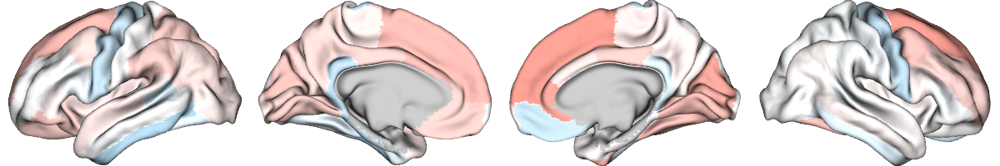

In [225]:
# plot t values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_ige_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

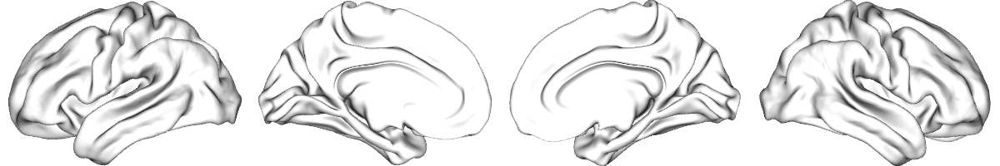

In [226]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [227]:
## Check which areas are significant in epilepsy
q_ctx_ige = pd.Series(result_dicts['q_ige_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index([], dtype='object')

In [228]:
len(q_ctx_ige[q_ctx_ige < 0.05])

0

In [229]:
result_dicts['t_ige_ctx'][1].min(), result_dicts['t_ige_ctx'][1].max()

(-1.234225759094846, 2.0169861435606915)

#### Sex age of onset interaction effects in interaction

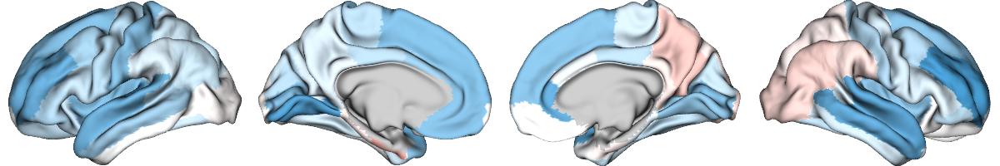

In [230]:
# plot t values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_ige_ctx'][3], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

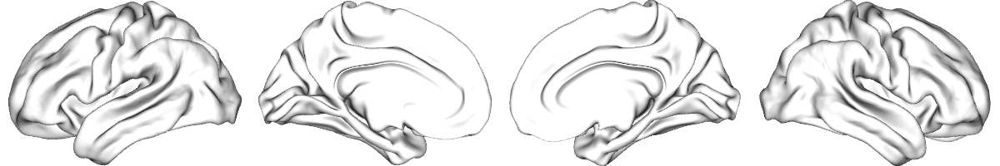

In [231]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [232]:
## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_ige_ctx'][3], index=ctx_ige.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [233]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [234]:
result_dicts['t_ige_ctx'][3].min(), result_dicts['t_ige_ctx'][3].max()

(-2.393812200470581, 1.3921866426476734)

### subcortical volume

Sex duration interaction

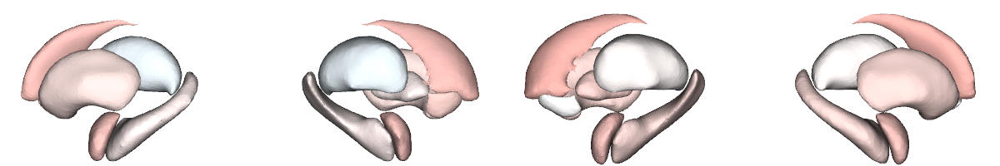

In [235]:
# plot t values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['t_ige_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-6, 6))

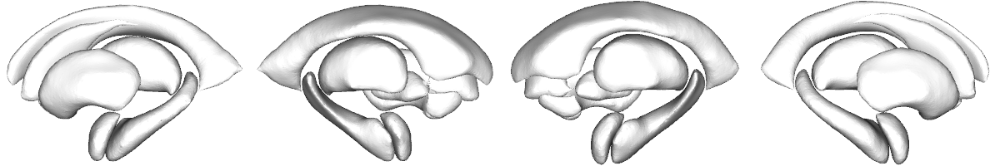

In [236]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [237]:
result_dicts['t_ige_sv'][1].min(), result_dicts['t_ige_sv'][1].max()

(-0.35069568833892056, 1.47869101796381)

Sex age of onset interaction effects

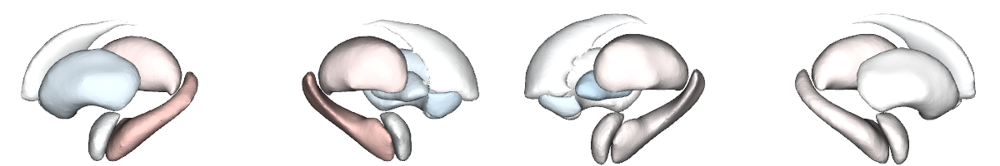

In [175]:
# plot t values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['t_ige_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

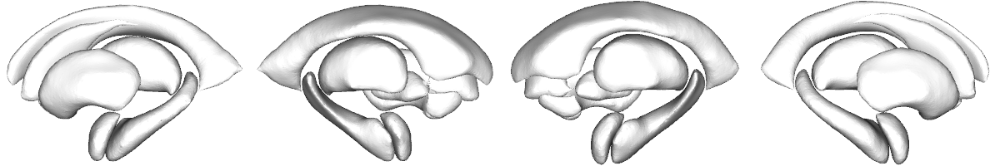

In [176]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [177]:
## Check which areas are significant in epilepsy
q_sv_hc = pd.Series(result_dicts['q_ige_sv'][3], index=sv_ige.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index([], dtype='object')

In [178]:
len(q_sv_hc[q_sv_hc < 0.05])

0

In [179]:
result_dicts['t_ige_sv'][3].min(), result_dicts['t_ige_sv'][3].max()

(-0.7560923679579562, 0.873830103492115)